# Merchant ranking v2 — revised after development validation

The original ten-feature ranking was diagnosed in `validation_timesplit.ipynb` using
March–August 2022 as a **development window**. That analysis showed that historical BNPL revenue
was by far the strongest signal and that v1's dollar-space shrinkage behaved badly for thin-history
merchants.

This notebook freezes the revised v2 design and then evaluates it on **September 2022, which was
not used to choose the weights**.

| Development finding | v2 change |
| --- | --- |
| Dollar-space shrinkage could pull tiny merchants upward | Shrink percentile ranks toward 50 |
| Past revenue dominated the development signal | Revenue becomes 70% of the score |
| Growth was useful but much weaker | Growth falls to 8% |
| Engagement, stability and activity add context rather than much prediction | Keep them small |
| Customer concentration is mainly a fragility/risk signal | Keep 5% |
| ABS variables barely separated merchants predictively | Keep 5% as customer-base/risk context |

The March–August figures are therefore **development results**, not the final performance claim.
The final untouched check is in §6.

**Run order:** `01_data_quality_eda.ipynb` → `validation_timesplit.ipynb` → this notebook.


In [1]:
from pathlib import Path

def find_project_root():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "tables").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate the project root. Run this notebook from inside the repository "
        "containing data/tables/."
    )

PROJECT_ROOT = find_project_root()
PROCESSED = PROJECT_ROOT / "data" / "tables" / "processed"

import numpy as np
import pandas as pd
from pyspark.sql import SparkSession, Window, functions as F

FEATURES_IN = PROCESSED / "merchant_features"

if not FEATURES_IN.exists():
    raise FileNotFoundError(
        f"{FEATURES_IN} is missing - run 01_data_quality_eda.ipynb first."
    )

spark = (
    SparkSession.builder.appName("MAST30034 Project 2 - Merchant ranking v2")
    .config("spark.sql.session.timeZone", "Etc/UTC")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")

merchant_features = spark.read.parquet(str(FEATURES_IN))
transactions = spark.read.parquet(str(PROCESSED / "transactions_clean"))
merchants = spark.read.parquet(str(PROCESSED / "merchants_clean"))
consumers = spark.read.parquet(str(PROCESSED / "consumers_sa2"))

print(f"merchant_features : {merchant_features.count():,} rows")
print(f"transactions      : {transactions.count():,} rows")


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/02 13:36:11 WARN Utils: Your hostname, Matts-MacBook-Pro.local, resolves to a loopback address: 127.0.0.1; using 100.94.55.71 instead (on interface en0)
26/10/02 13:36:11 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/02 13:36:11 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/02 13:36:12 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.


merchant_features : 4,422 rows
transactions      : 14,195,505 rows


## 1. Who can be ranked

Unchanged from v1: no metadata row means no take rate, and without a take rate there is no way to
say what the firm earns. Those merchants are reported, not hidden, and excluded from scoring.

New here: three **thin-evidence flags**. They remove nobody — §3's shrinkage handles thin evidence
— but they show whether a merchant near the top got there on 4,000 transactions or on 40.

In [2]:
eligible = merchant_features.filter(F.col("take_rate").isNotNull())
excluded = merchant_features.filter(F.col("take_rate").isNull())

n_all, n_ok, n_out = merchant_features.count(), eligible.count(), excluded.count()
print(f"merchants in table      : {n_all:,}")
print(f"rankable (has take rate): {n_ok:,}")
print(f"excluded (no metadata)  : {n_out:,}")

if n_out:
    excluded.agg(
        F.sum("transaction_count").alias("transactions"),
        F.round(F.sum("total_value") / 1e6, 2).alias("value_millions"),
    ).show()

merchants in table      : 4,422
rankable (has take rate): 4,026
excluded (no metadata)  : 396
+------------+--------------+
|transactions|value_millions|
+------------+--------------+
|      549947|        191.92|
+------------+--------------+



## 2. Features carried over from v1

`customer_hhi` — Herfindahl index of revenue across a merchant's customers; 1.0 means one customer
is the whole business. `repeat_rate` — share of customers who ordered more than once. Plus the
customer-base picture from `consumers_sa2`: weighted ABS income and IRSAD, and how much of the
base has ABS data behind it.

Unchanged. The validation said these were *weighted* wrongly, not computed wrongly.

In [3]:
per_customer = (
    transactions.groupBy("merchant_abn", "user_id")
    .agg(F.sum("dollar_value").alias("customer_gmv"),
         F.count("*").alias("customer_orders"))
)

concentration = (
    per_customer.groupBy("merchant_abn")
    .agg(
        (F.sum(F.when(F.col("customer_orders") > 1, 1).otherwise(0)) / F.count("*"))
            .alias("repeat_rate"),
        F.sum(F.pow("customer_gmv", 2)).alias("_sq"),
        F.sum("customer_gmv").alias("_tot"),
    )
    .withColumn("customer_hhi", F.col("_sq") / F.pow(F.col("_tot"), 2))
    .drop("_sq", "_tot")
)

has_income = F.col("abs_median_household_income_weekly").isNotNull()
has_irsad = F.col("seifa_irsad_decile").isNotNull()
w = F.coalesce(F.col("sa2_share"), F.lit(1.0))

cust_profile = per_customer.join(
    consumers.select("user_id", "state", "sa2_code", "sa2_share",
                     "abs_median_household_income_weekly", "seifa_irsad_decile"),
    on="user_id", how="left",
)

customer_base = (
    cust_profile.groupBy("merchant_abn")
    .agg(
        F.countDistinct("state").alias("n_states"),
        F.countDistinct("sa2_code").alias("n_sa2"),
        (F.sum(F.when(has_income, F.col("abs_median_household_income_weekly") * w))
         / F.sum(F.when(has_income, w))).alias("customer_income"),
        (F.sum(F.when(has_irsad, F.col("seifa_irsad_decile") * w))
         / F.sum(F.when(has_irsad, w))).alias("customer_irsad"),
        F.avg(F.when(has_income, 1.0).otherwise(0.0)).alias("pct_customers_with_abs"),
        # share of the customer base sitting in the most disadvantaged SEIFA deciles
        (F.sum(F.when(F.col("seifa_irsad_decile") <= 3, w))
         / F.sum(F.when(has_irsad, w))).alias("pct_customers_irsad_bottom3"),
    )
)

by_state = (cust_profile.groupBy("merchant_abn", "state")
                        .agg(F.countDistinct("user_id").alias("customers")))
wm = Window.partitionBy("merchant_abn")
top_state = (by_state
    .withColumn("share", F.col("customers") / F.sum("customers").over(wm))
    .groupBy("merchant_abn").agg(F.max("share").alias("pct_top_state")))

customer_base = customer_base.join(top_state, on="merchant_abn", how="left")

features = (
    eligible
    .join(concentration, on="merchant_abn", how="left")
    .join(customer_base, on="merchant_abn", how="left")
    .toPandas()
)

features["thin_transactions"] = features["transaction_count"] < 300
features["thin_history"] = features["active_months"] < 6
features["thin_abs_backing"] = features["pct_customers_with_abs"] < 0.5

OUT_F = PROCESSED / "merchant_ranking_v2_features.parquet"
features.to_parquet(OUT_F, index=False)
print(f"{len(features):,} rankable merchants -> {OUT_F.name}")
print("\nthin-evidence flags:")
for c in ["thin_transactions", "thin_history", "thin_abs_backing"]:
    print(f"  {c:20s} {features[c].sum():,} merchants")
features.head(3)

4,026 rankable merchants -> merchant_ranking_v2_features.parquet

thin-evidence flags:
  thin_transactions    1,820 merchants
  thin_history         71 merchants
  thin_abs_backing     3 merchants


,merchant_abn,name,keywords_clean,take_rate,transaction_count,total_value,avg_transaction_value,estimated_bnpl_revenue,unique_customers,transactions_per_customer,...,n_states,n_sa2,customer_income,customer_irsad,pct_customers_with_abs,pct_customers_irsad_bottom3,pct_top_state,thin_transactions,thin_history,thin_abs_backing
0,10023283211,Felis Limited,"[furniture, home furnishings and equipment sho...",0.18,3073,664813.600777,216.340254,1196.664481,2871,1.070359,...,8,1053,1580.116133,4.639719,0.832784,0.393361,0.294855,False,False,False
1,10142254217,Arcu Ac Orci Corporation,"[cable, satellite, and other pay television an...",4.22,2827,110401.559412,39.052550,4658.945807,2664,1.061186,...,8,1036,1591.331774,4.713437,0.838189,0.378277,0.284310,False,False,False
2,10165489824,Nunc Sed Company,"[jewelry, watch, clock, and silverware shops]",4.40,5,56180.473857,11236.094771,2471.940850,5,1.000000,...,4,4,1755.982513,5.723740,0.800000,0.273535,0.400000,True,True,False


## 3. Fix 1 — shrinkage in rank space, not dollar space

The single largest change, and the bug the validation exposed.

**v1:** `shrinkage = n / (n + 300)`, then

```
revenue_shrunk = shrinkage * revenue + (1 - shrinkage) * mean_revenue
```

`mean_revenue` is dragged upwards by a handful of giants, so a merchant with 40 transactions and
\$900 of revenue was pulled *up* towards it, landing above thousands of genuine mid-sized
businesses. The penalty for thin evidence was acting as a reward.

**v2:** rank first, then shrink the rank towards the middle:

```
rank_shrunk = shrinkage * rank + (1 - shrinkage) * 50
```

Thin evidence now moves a merchant towards the middle from wherever it sat, which is what "we do
not know enough about you yet" should mean. The cell below measures the damage v1 was doing.

In [4]:
K = 300

f = features.copy()
sh = f["transaction_count"] / (f["transaction_count"] + K)

# v1: shrink the dollars
v1_shrunk = sh * f["estimated_bnpl_revenue"] + (1 - sh) * f["estimated_bnpl_revenue"].mean()
v1_rank = v1_shrunk.rank(ascending=False, method="first")

# v2: shrink the rank
raw_rank_pct = f["estimated_bnpl_revenue"].rank(pct=True) * 100
v2_rank_pct = sh * raw_rank_pct + (1 - sh) * 50
v2_rank = v2_rank_pct.rank(ascending=False, method="first")

honest = f["estimated_bnpl_revenue"].rank(ascending=False, method="first")

print("Merchants with fewer than 100 transactions that the revenue term alone")
print("would place inside the top 500:\n")
thin = f["transaction_count"] < 100
print(f"  by raw revenue            : {(thin & (honest  <= 500)).sum():>4}")
print(f"  v1 (dollar shrinkage)     : {(thin & (v1_rank <= 500)).sum():>4}   <- inflated")
print(f"  v2 (rank shrinkage)       : {(thin & (v2_rank <= 500)).sum():>4}")

print("\nWhere v1 put the median thin merchant vs where v2 puts it:")
print(f"  v1 median rank of a sub-100-transaction merchant: {v1_rank[thin].median():,.0f}"
      f" of {len(f):,}")
print(f"  v2 median rank of the same merchants            : {v2_rank[thin].median():,.0f}"
      f" of {len(f):,}")

Merchants with fewer than 100 transactions that the revenue term alone
would place inside the top 500:

  by raw revenue            :   10
  v1 (dollar shrinkage)     :    0   <- inflated
  v2 (rank shrinkage)       :    0

Where v1 put the median thin merchant vs where v2 puts it:
  v1 median rank of a sub-100-transaction merchant: 1,588 of 4,026
  v2 median rank of the same merchants            : 2,526 of 4,026


## 4. Fix 2 — weights selected from the development evidence

The scoring machinery is unchanged: each feature becomes a percentile rank, missing features
receive the neutral value 50, and the final score is a weighted sum. Revenue and growth use the
rank-space shrinkage from §3.

The weights below were chosen **after inspecting the March–August development window**, so that
period must not be reused as the final test.

| Feature | v1 | **v2** | Role in v2 |
| --- | --- | --- | --- |
| `estimated_bnpl_revenue` | 30% | **70%** | dominant commercial signal in development |
| `log_value_growth` | 20% | **8%** | forward-looking context, but noisy |
| `transactions_per_customer` | 10% | **4%** | engagement |
| `repeat_rate` | 5% | **3%** | repeat purchasing |
| `stability` (−`value_cv`) | 10% | **3%** | preference for less volatile merchants |
| `active_month_ratio` | 5% | **2%** | evidence of an established track record |
| `customer_spread` (1−HHI) | 5% | **5%** | concentration/fragility risk |
| `customer_income` (ABS) | 5% | **3%** | customer-base context |
| `customer_irsad` (ABS) | 5% | **2%** | socio-economic area context |
| `unique_customers` | 5% | **0%** | removed to reduce double-counting of merchant size |

The 70% revenue weight is therefore a **development-selected modelling choice**. Its honest
assessment comes from the untouched September holdout in §6; the September result is not used to
retune it.


In [5]:
WEIGHTS_V2 = {
    "estimated_bnpl_revenue":    0.70,
    "log_value_growth":          0.08,
    "transactions_per_customer": 0.04,
    "repeat_rate":               0.03,
    "stability":                 0.03,
    "active_month_ratio":        0.02,
    "customer_spread":           0.05,
    "customer_income":           0.03,
    "customer_irsad":            0.02,
}
assert abs(sum(WEIGHTS_V2.values()) - 1) < 1e-9, sum(WEIGHTS_V2.values())

# the two features shrunk towards the middle when evidence is thin
SHRINK_IN_RANK_SPACE = {"estimated_bnpl_revenue", "log_value_growth"}

WEIGHTS_V1 = {
    "estimated_bnpl_revenue":    0.30,
    "log_value_growth":          0.20,
    "transactions_per_customer": 0.10,
    "stability":                 0.10,
    "unique_customers":          0.05,
    "active_month_ratio":        0.05,
    "repeat_rate":               0.05,
    "customer_income":           0.05,
    "customer_irsad":            0.05,
    "customer_spread":           0.05,
}


def derive(df):
    d = df.copy()
    d["stability"] = -d["value_cv"]              # lower volatility is better
    d["customer_spread"] = 1 - d["customer_hhi"]  # less concentration is better
    return d


def score_v2(df, weights=WEIGHTS_V2, k=K, shrink=SHRINK_IN_RANK_SPACE):
    d = derive(df)
    shrinkage = d["transaction_count"] / (d["transaction_count"] + k)
    ranks = pd.DataFrame(
        {c: d[c].rank(pct=True, na_option="keep") * 100 for c in weights}
    ).fillna(50.0)
    for c in shrink & set(weights):
        ranks[c] = shrinkage * ranks[c] + (1 - shrinkage) * 50.0
    return sum(ranks[c] * wt for c, wt in weights.items()), ranks


def score_v1(df, weights=WEIGHTS_V1, k=K):
    # kept exactly as the baseline notebook had it, so the comparison is fair
    d = derive(df)
    shrinkage = d["transaction_count"] / (d["transaction_count"] + k)
    for raw in ("estimated_bnpl_revenue", "log_value_growth"):
        d[raw] = shrinkage * d[raw] + (1 - shrinkage) * d[raw].mean()
    ranks = pd.DataFrame(
        {c: d[c].rank(pct=True, na_option="keep") * 100 for c in weights}
    ).fillna(50.0)
    return sum(ranks[c] * wt for c, wt in weights.items()), ranks


f = derive(features)
f["score"], ranks_v2 = score_v2(features)
f["score_v1"] = score_v1(features)[0]
f["rank_overall"] = f["score"].rank(ascending=False, method="first").astype(int)
f["rank_v1"] = f["score_v1"].rank(ascending=False, method="first").astype(int)

order = f.sort_values("rank_overall").index
f = f.loc[order].reset_index(drop=True)
ranks_v2 = ranks_v2.loc[order].reset_index(drop=True)

top100 = f[f["rank_overall"] <= 100]
rev_total = f["estimated_bnpl_revenue"].sum()

print(f"top 100 of {len(f):,} rankable merchants")
print(f"  share of all estimated BNPL revenue : "
      f"{top100['estimated_bnpl_revenue'].sum() / rev_total:.1%}"
      f"   (v1 top 100 held "
      f"{f.nsmallest(100, 'rank_v1')['estimated_bnpl_revenue'].sum() / rev_total:.1%})")
print(f"  median transactions                 : {top100['transaction_count'].median():,.0f}"
      f"   (all merchants {f['transaction_count'].median():,.0f})")
print(f"  carrying a thin-evidence flag       : "
      f"{top100[['thin_transactions','thin_history','thin_abs_backing']].any(axis=1).sum()}"
      f" of 100")
print(f"  overlap with the v1 top 100         : "
      f"{len(set(top100['merchant_abn']) & set(f.nsmallest(100, 'rank_v1')['merchant_abn']))}/100")

show = ["rank_overall", "rank_v1", "name", "take_rate", "estimated_bnpl_revenue",
        "transaction_count", "log_value_growth", "customer_hhi",
        "customer_income", "customer_irsad", "pct_customers_with_abs", "score"]
top100[show].head(20).round(3)

top 100 of 4,026 rankable merchants
  share of all estimated BNPL revenue : 30.4%   (v1 top 100 held 24.3%)
  median transactions                 : 26,974   (all merchants 399)
  carrying a thin-evidence flag       : 0 of 100
  overlap with the v1 top 100         : 62/100


,rank_overall,rank_v1,name,take_rate,estimated_bnpl_revenue,transaction_count,log_value_growth,customer_hhi,customer_income,customer_irsad,pct_customers_with_abs,score
0,1,11,Dignissim Maecenas Foundation,6.64,590673.669,62814,0.358,0.0,1583.430,4.683,0.836,92.969
1,2,5,Arcu Sed Eu Incorporated,4.80,432454.148,35930,0.363,0.0,1584.375,4.692,0.836,92.812
2,3,35,Leo In Consulting,6.43,581136.253,258319,0.340,0.0,1583.020,4.679,0.835,92.748
3,4,28,Mauris Non Institute,6.10,544064.200,114164,0.346,0.0,1583.228,4.679,0.835,92.691
4,5,2,Odio Phasellus Institute,6.59,536062.144,10826,0.388,0.0,1588.933,4.720,0.836,92.618
5,6,14,Ornare Limited,5.91,548590.520,29496,0.361,0.0,1583.935,4.677,0.838,92.618
6,7,48,Lobortis Ultrices Company,6.31,529710.790,107421,0.336,0.0,1583.630,4.681,0.835,92.510
7,8,45,Est Nunc Consulting,6.01,506253.308,204232,0.341,0.0,1583.016,4.679,0.835,92.500
8,9,71,Lacus Consulting,6.98,555429.641,216173,0.337,0.0,1583.020,4.679,0.835,92.381
9,10,40,Non Vestibulum Industries,5.80,393436.293,234145,0.341,0.0,1583.058,4.679,0.835,92.376


## 5. ABS, given a job it can actually do

In the March–August **development** analysis, the ABS customer-base features carried almost no
incremental association with realised merchant revenue. In this synthetic dataset, customer
profiles are similar across merchants, so area-level income and IRSAD do little to separate them.

That does not make the external data useless. Its defensible role is as a **portfolio and risk
lens**:

- how much of the shortlist's customer base sits in disadvantaged SEIFA areas;
- whether the shortlist is geographically concentrated;
- whether a merchant's customer profile rests on thin ABS coverage.

The caveat remains essential: these are **area statistics**, not individual customer incomes or
individual socio-economic status. They should not be interpreted as facts about a person.


In [6]:
def abs_profile(df, label):
    return {
        "group": label,
        "merchants": len(df),
        "median customer_income ($/wk)": df["customer_income"].median(),
        "median customer_irsad (decile)": df["customer_irsad"].median(),
        "mean % customers in IRSAD 1-3": df["pct_customers_irsad_bottom3"].mean(),
        "mean ABS coverage of base": df["pct_customers_with_abs"].mean(),
        "median states reached": df["n_states"].median(),
        "median SA2s reached": df["n_sa2"].median(),
    }


profile = pd.DataFrame([
    abs_profile(top100, "v2 top 100"),
    abs_profile(f.nsmallest(100, "rank_v1"), "v1 top 100"),
    abs_profile(f.nlargest(100, "estimated_bnpl_revenue"), "baseline: top 100 by revenue"),
    abs_profile(f, "all rankable merchants"),
]).set_index("group")

print("How alike the customer bases are - this is why ABS cannot separate merchants here:")
print(f"  customer_income across merchants: "
      f"{f['customer_income'].quantile(0.05):,.0f} to {f['customer_income'].quantile(0.95):,.0f}"
      f" $/wk (5th-95th percentile), median {f['customer_income'].median():,.0f}")
print(f"  customer_irsad across merchants : "
      f"{f['customer_irsad'].quantile(0.05):.2f} to {f['customer_irsad'].quantile(0.95):.2f}"
      f" (5th-95th), median {f['customer_irsad'].median():.2f}")
print()
profile.round(3).T

How alike the customer bases are - this is why ABS cannot separate merchants here:
  customer_income across merchants: 1,483 to 1,668 $/wk (5th-95th percentile), median 1,583
  customer_irsad across merchants : 4.15 to 5.13 (5th-95th), median 4.68



group,v2 top 100,v1 top 100,baseline: top 100 by revenue,all rankable merchants
merchants,100.000,100.000,100.000,4026.000
median customer_income ($/wk),1583.272,1583.410,1582.984,1582.835
median customer_irsad (decile),4.679,4.681,4.679,4.679
mean % customers in IRSAD 1-3,0.387,0.386,0.388,0.393
mean ABS coverage of base,0.835,0.835,0.835,0.835
median states reached,8.000,8.000,8.000,8.000
median SA2s reached,1487.000,1469.500,1479.500,283.000


In [7]:
# merchants on the shortlist whose customer base leans to the most disadvantaged deciles,
# or whose ABS picture rests on too little coverage to be trusted
watch = top100[(top100["pct_customers_irsad_bottom3"] > top100["pct_customers_irsad_bottom3"].median())
               | top100["thin_abs_backing"]]

print(f"{len(watch)} of the top 100 carry an ABS caution flag "
      "(above-median exposure to IRSAD deciles 1-3, or ABS coverage below 50%)")
print("\nThese are not exclusions - they are what a credit committee should see:")
watch[["rank_overall", "name", "estimated_bnpl_revenue", "customer_irsad",
       "pct_customers_irsad_bottom3", "pct_customers_with_abs", "n_states"]] \
    .head(12).round(3)

50 of the top 100 carry an ABS caution flag (above-median exposure to IRSAD deciles 1-3, or ABS coverage below 50%)

These are not exclusions - they are what a credit committee should see:


,rank_overall,name,estimated_bnpl_revenue,customer_irsad,pct_customers_irsad_bottom3,pct_customers_with_abs,n_states
2,3,Leo In Consulting,581136.253,4.679,0.388,0.835,8
5,6,Ornare Limited,548590.520,4.677,0.389,0.838,8
6,7,Lobortis Ultrices Company,529710.790,4.681,0.388,0.835,8
7,8,Est Nunc Consulting,506253.308,4.679,0.388,0.835,8
8,9,Lacus Consulting,555429.641,4.679,0.388,0.835,8
10,11,Phasellus At Limited,411221.752,4.670,0.388,0.833,8
11,12,Dictum Phasellus In Institute,487424.129,4.679,0.388,0.835,8
12,13,Lorem Ipsum Sodales Industries,382698.884,4.679,0.388,0.835,8
17,18,Nullam Consulting,428716.214,4.677,0.388,0.835,8
18,19,Ultricies Dignissim LLP,356409.380,4.679,0.389,0.835,8


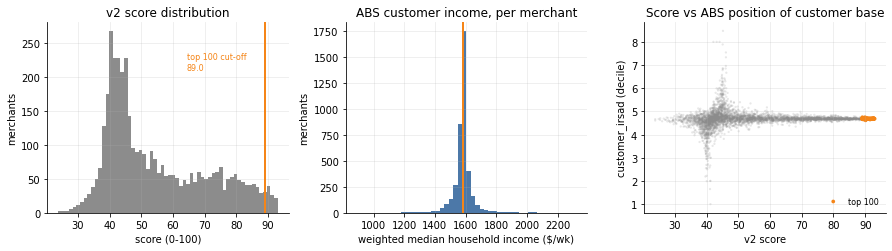

Read the third panel as the ABS caveat in one picture: the cloud is flat, so the
socio-economic position of a customer base barely moves with merchant quality in
this data. The 5% weight is sized to that picture.


In [8]:
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GREY = "#4C78A8", "#F58518", "#8C8C8C"

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))

axes[0].hist(f["score"], bins=60, color=GREY)
cut = top100["score"].min()
axes[0].axvline(cut, color=ORANGE, linewidth=2)
axes[0].annotate(f"top 100 cut-off\n{cut:.1f}", (cut, axes[0].get_ylim()[1] * 0.75),
                 xytext=(-78, 0), textcoords="offset points", color=ORANGE, fontsize=8)
axes[0].set_title("v2 score distribution")
axes[0].set_xlabel("score (0-100)"); axes[0].set_ylabel("merchants")

axes[1].hist(f["customer_income"].dropna(), bins=50, color=BLUE)
axes[1].axvline(f["customer_income"].median(), color=ORANGE, linewidth=2)
axes[1].set_title("ABS customer income, per merchant")
axes[1].set_xlabel("weighted median household income ($/wk)")
axes[1].set_ylabel("merchants")

axes[2].scatter(f["score"], f["customer_irsad"], s=5, alpha=0.2, color=GREY,
                edgecolors="none")
axes[2].scatter(top100["score"], top100["customer_irsad"], s=14, color=ORANGE,
                edgecolors="none", label="top 100")
axes[2].set_title("Score vs ABS position of customer base")
axes[2].set_xlabel("v2 score"); axes[2].set_ylabel("customer_irsad (decile)")
axes[2].legend(frameon=False, loc="lower right", fontsize=8)

plt.tight_layout(); plt.show()

print("Read the third panel as the ABS caveat in one picture: the cloud is flat, so the")
print("socio-economic position of a customer base barely moves with merchant quality in")
print("this data. The 5% weight is sized to that picture.")

## 6. Final untouched holdout — September 2022

The v2 weights above are now frozen.

For the final check, features are rebuilt using all complete information available **before**
September: 1 March 2021 through 31 August 2022. The next complete month, 1–30 September 2022,
is held out and used only for evaluation.

October is not used because the dataset ends during that month.

This is the first point where September is inspected. Do not use the result below to change the
weights; otherwise it stops being an untouched holdout.


In [9]:
HISTORY_START, HISTORY_END = "2021-03-01", "2022-08-31"
HOLDOUT_START, HOLDOUT_END = "2022-09-01", "2022-09-30"

history_tx = transactions.filter(
    F.col("order_datetime").between(HISTORY_START, HISTORY_END)
)
holdout_tx = transactions.filter(
    F.col("order_datetime").between(HOLDOUT_START, HOLDOUT_END)
)

print(f"history : {history_tx.count():,} transactions")
print(f"holdout : {holdout_tx.count():,} transactions")


def build_features(
    tx,
    months_in_window,
    early_start,
    early_end_exclusive,
    recent_start,
    recent_end_exclusive,
    window_start,
    window_end,
):
    core = (
        tx.groupBy("merchant_abn")
        .agg(
            F.sum("dollar_value").alias("gmv"),
            F.count("*").alias("transaction_count"),
            F.countDistinct("user_id").alias("unique_customers"),
            F.countDistinct(F.trunc("order_datetime", "month")).alias("active_months"),
        )
        .withColumn(
            "transactions_per_customer",
            F.col("transaction_count") / F.col("unique_customers"),
        )
        .withColumn(
            "active_month_ratio",
            F.col("active_months") / F.lit(months_in_window),
        )
    )

    per_cust = (
        tx.groupBy("merchant_abn", "user_id")
        .agg(
            F.sum("dollar_value").alias("cust_gmv"),
            F.count("*").alias("cust_orders"),
        )
    )

    conc = (
        per_cust.groupBy("merchant_abn")
        .agg(
            (
                F.sum(F.when(F.col("cust_orders") > 1, 1).otherwise(0))
                / F.count("*")
            ).alias("repeat_rate"),
            F.sum(F.pow("cust_gmv", 2)).alias("_sq"),
            F.sum("cust_gmv").alias("_tot"),
        )
        .withColumn("customer_hhi", F.col("_sq") / F.pow(F.col("_tot"), 2))
        .drop("_sq", "_tot")
    )

    monthly = (
        tx.withColumn("month", F.trunc("order_datetime", "month"))
        .groupBy("merchant_abn", "month")
        .agg(F.sum("dollar_value").alias("monthly_gmv"))
    )

    month_starts = [
        (d.date(),)
        for d in pd.date_range(
            start=pd.Timestamp(window_start).replace(day=1),
            end=pd.Timestamp(window_end).replace(day=1),
            freq="MS",
        )
    ]
    complete_months = spark.createDataFrame(month_starts, ["month"])
    merchant_ids = tx.select("merchant_abn").distinct()

    monthly_complete = (
        merchant_ids.crossJoin(complete_months)
        .join(monthly, ["merchant_abn", "month"], "left")
        .fillna({"monthly_gmv": 0.0})
    )

    stab = (
        monthly_complete.groupBy("merchant_abn")
        .agg(
            F.avg("monthly_gmv").alias("mean_monthly_value"),
            F.stddev("monthly_gmv").alias("sd_monthly_value"),
        )
        .withColumn(
            "value_cv",
            F.when(
                F.col("mean_monthly_value") > 0,
                F.col("sd_monthly_value") / F.col("mean_monthly_value"),
            ),
        )
    )

    def three_month_block(start, end_exclusive, prefix):
        return (
            tx.filter(
                (F.col("order_datetime") >= F.lit(start))
                & (F.col("order_datetime") < F.lit(end_exclusive))
            )
            .groupBy("merchant_abn")
            .agg(
                F.sum("dollar_value").alias(f"{prefix}_3m_value"),
                F.countDistinct(F.trunc("order_datetime", "month")).alias(
                    f"{prefix}_active_months"
                ),
            )
        )

    early = three_month_block(early_start, early_end_exclusive, "early")
    recent = three_month_block(recent_start, recent_end_exclusive, "recent")

    growth = (
        early.join(recent, "merchant_abn", "full")
        .fillna(
            {
                "early_3m_value": 0.0,
                "recent_3m_value": 0.0,
                "early_active_months": 0,
                "recent_active_months": 0,
            }
        )
        .withColumn(
            "log_value_growth",
            F.when(
                (F.col("early_active_months") >= 2)
                & (F.col("recent_active_months") >= 2),
                F.log1p("recent_3m_value") - F.log1p("early_3m_value"),
            ),
        )
    )

    cp = per_cust.join(
        consumers.select(
            "user_id",
            "state",
            "sa2_code",
            "sa2_share",
            "abs_median_household_income_weekly",
            "seifa_irsad_decile",
        ),
        on="user_id",
        how="left",
    )

    has_income = F.col("abs_median_household_income_weekly").isNotNull()
    has_irsad = F.col("seifa_irsad_decile").isNotNull()
    wt = F.coalesce(F.col("sa2_share"), F.lit(1.0))

    base = (
        cp.groupBy("merchant_abn")
        .agg(
            (
                F.sum(
                    F.when(
                        has_income,
                        F.col("abs_median_household_income_weekly") * wt,
                    )
                )
                / F.sum(F.when(has_income, wt))
            ).alias("customer_income"),
            (
                F.sum(F.when(has_irsad, F.col("seifa_irsad_decile") * wt))
                / F.sum(F.when(has_irsad, wt))
            ).alias("customer_irsad"),
            F.avg(F.when(has_income, 1.0).otherwise(0.0)).alias(
                "pct_customers_with_abs"
            ),
        )
    )

    return (
        core.join(conc, "merchant_abn", "left")
        .join(stab.select("merchant_abn", "value_cv"), "merchant_abn", "left")
        .join(growth.select("merchant_abn", "log_value_growth"), "merchant_abn", "left")
        .join(base, "merchant_abn", "left")
        .join(
            merchants.select("merchant_abn", "name", "take_rate"),
            "merchant_abn",
            "left",
        )
        .withColumn(
            "estimated_bnpl_revenue",
            F.col("gmv") * F.col("take_rate") / 100.0,
        )
    )


history_pd = (
    build_features(
        history_tx,
        months_in_window=18,
        early_start="2021-03-01",
        early_end_exclusive="2021-06-01",
        recent_start="2022-06-01",
        recent_end_exclusive="2022-09-01",
        window_start=HISTORY_START,
        window_end=HISTORY_END,
    )
    .filter(F.col("take_rate").isNotNull())
    .toPandas()
)

assert history_pd["active_month_ratio"].le(1.0 + 1e-12).all(), (
    "active_month_ratio exceeded 1; check months_in_window"
)

realised = (
    holdout_tx.groupBy("merchant_abn")
    .agg(
        F.sum("dollar_value").alias("holdout_gmv"),
        F.count("*").alias("holdout_transactions"),
    )
    .join(merchants.select("merchant_abn", "take_rate"), "merchant_abn", "left")
    .withColumn(
        "realised_revenue",
        F.col("holdout_gmv") * F.col("take_rate") / 100.0,
    )
    .select(
        "merchant_abn",
        "holdout_gmv",
        "holdout_transactions",
        "realised_revenue",
    )
    .toPandas()
)

ev = history_pd.merge(realised, on="merchant_abn", how="left")
ev[["holdout_gmv", "holdout_transactions", "realised_revenue"]] = (
    ev[["holdout_gmv", "holdout_transactions", "realised_revenue"]].fillna(0.0)
)

print(f"\n{len(ev):,} merchants rankable before September")
print(f"trading in September : {(ev['holdout_transactions'] > 0).sum():,}")
print(f"no September activity: {(ev['holdout_transactions'] == 0).sum():,}")
print(
    f"September realised BNPL revenue: "
    f"${ev['realised_revenue'].sum()/1e6:,.2f}M"
)


history : 12,623,670 transactions
holdout : 817,096 transactions



4,026 merchants rankable before September
trading in September : 3,787
no September activity: 239
September realised BNPL revenue: $5.52M


In [10]:
from scipy.stats import spearmanr

perfect = ev.nlargest(100, "realised_revenue")
best_possible = perfect["realised_revenue"].sum()
perfect_abns = set(perfect["merchant_abn"])


def judge(label, series):
    sel = ev.assign(_s=series).nlargest(100, "_s")
    return {
        "picker": label,
        "spearman": spearmanr(series, ev["realised_revenue"])[0],
        "capture rate": sel["realised_revenue"].sum() / best_possible,
        "hits in realised top 100": len(set(sel["merchant_abn"]) & perfect_abns),
        "picks with no September activity": int(
            (sel["holdout_transactions"] == 0).sum()
        ),
        "realised revenue ($M)": sel["realised_revenue"].sum() / 1e6,
    }


s_v2, ranks_ev = score_v2(ev)
s_v1, _ = score_v1(ev)

results = pd.DataFrame([
    judge("v1 (original score)", s_v1),
    judge("v2 (frozen before holdout)", s_v2),
    judge(
        "baseline: past revenue",
        ev["estimated_bnpl_revenue"].rank(pct=True) * 100,
    ),
    judge("perfect foresight", ev["realised_revenue"]),
]).set_index("picker")

results.round(3)


,spearman,capture rate,hits in realised top 100,picks with no September activity,realised revenue ($M)
picker,,,,,
v1 (original score),0.74,0.645,46,0,1.244
v2 (frozen before holdout),0.90,0.867,73,0,1.671
baseline: past revenue,0.94,1.000,99,0,1.928
perfect foresight,1.00,1.000,100,0,1.929


### No September weight sweep

There is intentionally **no search over alternative v2 weights on the September holdout**.
March–August was the development window where the model architecture and weights were chosen.
September is used once to estimate how that frozen choice generalises.

If a different weighting looks attractive after seeing September, it should be recorded as future
work rather than substituted into the final result.


In [11]:
HOLDOUT_RESULTS = PROCESSED / "v2_holdout_results.csv"
results.to_csv(HOLDOUT_RESULTS)
print(f"Saved untouched holdout results -> {HOLDOUT_RESULTS.name}")


Saved untouched holdout results -> v2_holdout_results.csv


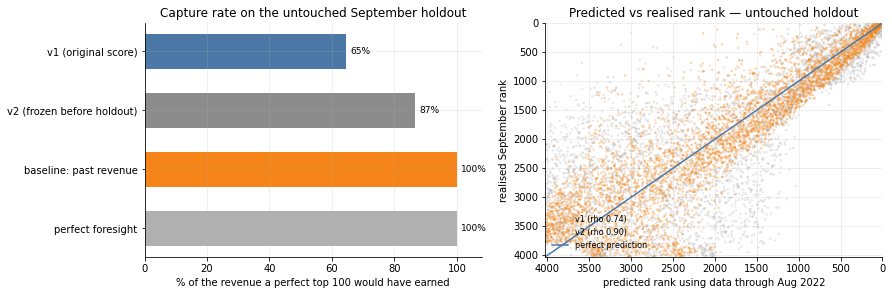

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

caps = results["capture rate"] * 100
bars = axes[0].barh(
    caps.index[::-1],
    caps.values[::-1],
    color=[BLUE, GREY, ORANGE, "#B0B0B0"][::-1],
    height=0.6,
)
axes[0].bar_label(
    bars,
    labels=[f"{v:.0f}%" for v in caps.values[::-1]],
    padding=4,
    fontsize=9,
)
axes[0].set_xlim(0, 108)
axes[0].set_xlabel("% of the revenue a perfect top 100 would have earned")
axes[0].set_title("Capture rate on the untouched September holdout")

pred_v2 = s_v2.rank(ascending=False, method="first")
pred_v1 = s_v1.rank(ascending=False, method="first")
realised_rank = ev["realised_revenue"].rank(ascending=False, method="first")
lim = len(ev)

axes[1].scatter(
    pred_v1,
    realised_rank,
    s=6,
    alpha=0.2,
    color=GREY,
    edgecolors="none",
    label=f"v1 (rho {results.loc['v1 (original score)', 'spearman']:.2f})",
)
axes[1].scatter(
    pred_v2,
    realised_rank,
    s=6,
    alpha=0.35,
    color=ORANGE,
    edgecolors="none",
    label=(
        "v2 "
        f"(rho {results.loc['v2 (frozen before holdout)', 'spearman']:.2f})"
    ),
)
axes[1].plot(
    [1, lim],
    [1, lim],
    color=BLUE,
    linewidth=1.5,
    label="perfect prediction",
)
axes[1].set_xlim(0, lim)
axes[1].set_ylim(0, lim)
axes[1].invert_xaxis()
axes[1].invert_yaxis()
axes[1].set_xlabel("predicted rank using data through Aug 2022")
axes[1].set_ylabel("realised September rank")
axes[1].set_title("Predicted vs realised rank — untouched holdout")
axes[1].legend(frameon=False, loc="lower left", fontsize=8)

plt.tight_layout()
plt.show()


## 7. How to report v2

Use the table in §6 as the **final out-of-sample result**. The March–August analysis belongs to
model development and should be described that way.

The comparison against past revenue remains essential. If v2 is below the baseline on September,
that is a valid finding: the richer score adds diversification, risk and customer-base context but
does not improve pure revenue capture in this synthetic dataset. If v2 exceeds it, report the
magnitude without changing the model after the fact.

After this one-time holdout check, the production shortlist in the first half of this notebook may
still be rebuilt on all available complete data, including September. That is ordinary refitting
after model selection; it does not change the holdout performance estimate.

**Limitations**

- September is untouched but only one month, so the estimate is clean with respect to tuning but
  still statistically narrow.
- ABS variables are area-level characteristics, not individual customer attributes.
- Take rate is assumed constant because the dataset supplies one value per merchant.
- Merchants without usable metadata/take rate cannot be ranked.
- Fraud is handled separately; this ranking is the pre-fraud commercial score.


In [13]:
OUT_RANK = PROCESSED / "merchant_ranking_v2.parquet"
OUT_CSV = PROCESSED / "top100_v2.csv"
HOLDOUT_RESULTS = PROCESSED / "v2_holdout_results.csv"

f.to_parquet(OUT_RANK, index=False)
top100.to_csv(OUT_CSV, index=False)
pd.Series(WEIGHTS_V2).to_csv(PROCESSED / "weights_v2.csv", header=["weight"])

# `results` is produced by the untouched September evaluation in §6.
if "results" in globals():
    results.to_csv(HOLDOUT_RESULTS)

print("written:")
for p in (
    OUT_RANK,
    OUT_CSV,
    PROCESSED / "weights_v2.csv",
    HOLDOUT_RESULTS,
):
    print(f"  {p.name}")
print(
    f"\n{len(top100)} merchants in the final full-data shortlist, "
    f"{len(f):,} ranked in total"
)


written:
  merchant_ranking_v2.parquet
  top100_v2.csv
  weights_v2.csv
  v2_holdout_results.csv

100 merchants in the final full-data shortlist, 4,026 ranked in total
